# Vorwärtstransformation des Roboters (symbolisch)

Konvention: **Standard-DH**

$$
{}^{i-1}T_i = R_z(\theta_i)\,T_z(d_i)\,T_x(a_i)\,R_x(\alpha_i)
$$

Aufbau des Notebooks:
1. Imports und Hilfsfunktion `dh_matrix`
2. Gelenkvariablen und Startkonfiguration
3. Parameter der Gelenke und feste Transformationen
4. Gesamttransformation (symbolisch)
5. Auswertung (Startkonfiguration, beliebige Winkel)

## 1. Imports und Hilfsfunktion

In [1]:
import sympy as sp

sp.init_printing(use_unicode=True)


def dh_matrix(theta, d, a, alpha):
    """
    Symbolische DH-Matrix (Standard-DH).
    theta : Gelenkwinkel um z_{i-1}  [rad]  (Zahl oder sympy-Symbol)
    d     : Verschiebung entlang z_{i-1}  [Laengeneinheit]
    a     : Verschiebung entlang x_i  [Laengeneinheit]
    alpha : Verdrehung um x_i  [rad]
    """
    ct, st = sp.cos(theta), sp.sin(theta)
    ca, sa = sp.cos(alpha), sp.sin(alpha)
    return sp.Matrix([
        [ct, -st * ca,  st * sa, a * ct],
        [st,  ct * ca, -ct * sa, a * st],
        [0,        sa,       ca,      d],
        [0,         0,        0,      1],
    ])

## 2. Gelenkvariablen und Startkonfiguration

In [2]:
# Gelenkvariablen
theta1, theta2, theta3, theta4 = sp.symbols("theta1 theta2 theta3 theta4", real=True)

# Startkonfiguration des Roboters (in Creo asm festgelegt)
start_config = {
    theta1: sp.rad(180),
    theta2: sp.rad(90),
    theta3: sp.rad(90),
    theta4: sp.rad(90),
}

## 3. Gelenkparameter und feste Transformationen

### Gelenk 1 (mit fester Verschiebung `trans_1` davor)

In [3]:
d1     = 67.7532
a1     = 0
alpha1 = sp.rad(-90)   # [rad]
dh1 = dh_matrix(theta1, d1, a1, alpha1)

trans_1 = sp.Matrix([
    [1, 0, 0, 0.0855906],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1],
])

### Gelenk 2

In [4]:
d2     = 0
a2     = -100
alpha2 = sp.rad(0)   # [rad]
dh2 = dh_matrix(theta2, d2, a2, alpha2)

### Gelenk 3

In [5]:
d3     = 0
a3     = 100
alpha3 = sp.rad(0)   # [rad]
dh3 = dh_matrix(theta3, d3, a3, alpha3)

### Gelenk 4 (mit fester Verschiebung `trans_4` davor)

In [6]:
d4     = 0
a4     = -110
alpha4 = sp.rad(90)   # [rad]
dh4 = dh_matrix(theta4, d4, a4, alpha4)

trans_4 = sp.Matrix([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 3],
    [0, 0, 0, 1],
])

## 4. Gesamttransformation 

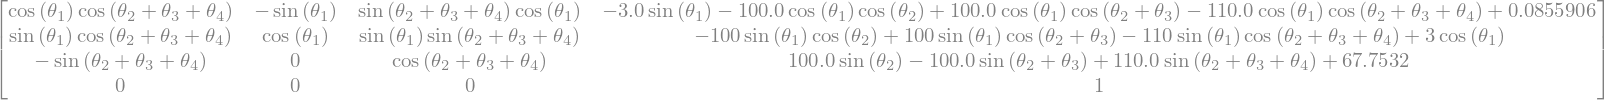

In [7]:
T = (trans_1 * dh1 * dh2 * dh3 * trans_4 * dh4).applyfunc(sp.trigsimp)
T

## 5. Auswertung

### Numerische Funktion für beliebige Gelenkwinkel (Radiant)

In [10]:
T_func = sp.lambdify((theta1, theta2, theta3, theta4), T, "numpy")

def T_num(q1, q2, q3, q4):
    """Gesamttransformation als numpy-Array fuer Gelenkwinkel in Radiant."""
    return T_func(q1, q2, q3, q4)

### Startkonfiguration einsetzen

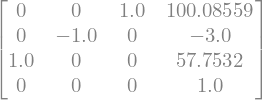

In [11]:
T_start = T.subs(start_config).evalf(8)
T_start.applyfunc(lambda x: 0 if abs(x) < 1e-9 else x)

### Beliebige Konfiguration testen

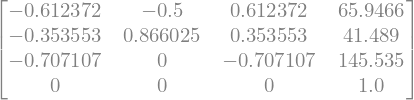

In [12]:
T_beispiel = T.subs({theta1: sp.rad(30), theta2: sp.rad(45),
                     theta3: sp.rad(0),  theta4: sp.rad(90)})
T_beispiel.evalf(6)